# 01 · Phase I: Why does FinBERT give *Neutral* tweets a sentiment?
**AI & Vis UE · Phase I (black box) · AI-aided pair: Dharmik & Sarang**

Input: `results_train.csv` from `00_baseline_finbert.ipynb` (train split, 9.5k tweets; FinBERT never saw them).
Uses only FinBERT's inputs, outputs and softmax scores. No other model (group decision); topic groups come from plain word counts (TF-IDF).

| Part | Question |
|---|---|
| A · Overview | Where do the errors come from, per class and in %? Is FinBERT overconfident? |
| B · Neutral direction | Which words push Neutral tweets to Bearish/Bullish? Are these errors confident? Which topics? Tweets with several companies? |
| C · Other systematic slices | Signed price moves, mixed cues |
| D · Manual review | Export a sample to judge: clear model mistake or ambiguous label? |

Every pattern is tested on the full split (Fisher's exact test, 95% Wilson intervals).

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)

SPLIT = "train"
BLUE, ORANGE, GRAY, INK, LIGHT = "#2a78d6", "#eb6834", "#8c8b85", "#52514e", "#d6d5ce"
CLS = {"Bearish": ORANGE, "Neutral": GRAY, "Bullish": BLUE}
ORDER = ["Bearish", "Neutral", "Bullish"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c8c7c0",
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110})
import os; os.makedirs("figures", exist_ok=True)

d = pd.read_csv(f"results_{SPLIT}.csv")
d["err"] = ~d["correct"]; T = d.text.str.lower()
BASE = d.err.mean(); e = d[d.err]
print(f"{len(d)} tweets · accuracy {1-BASE:.3f} · {d.err.sum()} errors")

def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / den; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return c - h, c + h

def test(mask):
    k, n = d.err[mask].sum(), mask.sum(); k2, n2 = d.err[~mask].sum(), (~mask).sum()
    return k, n, fisher_exact([[k, n-k], [k2, n2-k2]])[1]

9543 tweets · accuracy 0.712 · 2747 errors


## A · Overview

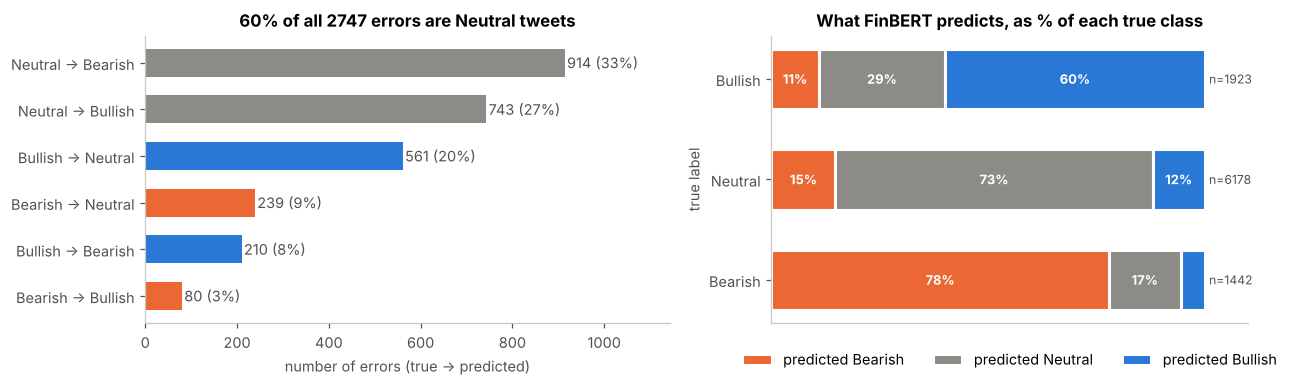

pred,Bearish,Neutral,Bullish
true,,,
Bearish,0.779,0.166,0.055
Neutral,0.148,0.732,0.120
Bullish,0.109,0.292,0.599


In [2]:
# A1 · Errors in counts AND as % of each true class (a class can dominate counts just by being large)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
et = e.groupby(["true", "pred"]).size().rename("n").reset_index().sort_values("n")
et["label"] = et.true + " → " + et.pred
bars = a1.barh(et.label, et.n, color=[CLS[t] for t in et.true], height=.6)
for b, n in zip(bars, et.n): a1.text(b.get_width() + 5, b.get_y() + b.get_height()/2, f"{n} ({n/len(e):.0%})", va="center", color=INK)
a1.set_xlim(0, et.n.max() * 1.25); a1.set_xlabel("number of errors (true → predicted)")
a1.set_title(f"{(e.true == 'Neutral').mean():.0%} of all {len(e)} errors are Neutral tweets")

cm = pd.crosstab(d.true, d.pred, normalize="index").reindex(index=ORDER, columns=ORDER)
left = np.zeros(3)
for c in ORDER:
    a2.barh(ORDER, cm[c], left=left, color=CLS[c], height=.6, edgecolor="white", linewidth=2, label=f"predicted {c}")
    for i, v in enumerate(cm[c]):
        if v > .06: a2.text(left[i] + v/2, i, f"{v:.0%}", ha="center", va="center", color="white", weight="bold", fontsize=8.5)
    left += cm[c].values
for i, c in enumerate(ORDER): a2.text(1.01, i, f"n={(d.true == c).sum()}", va="center", color=INK, fontsize=8)
a2.set_xlim(0, 1.1); a2.set_xticks([]); a2.set_ylabel("true label")
a2.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.05), ncol=3)
a2.set_title("What FinBERT predicts, as % of each true class")
plt.tight_layout(); plt.savefig("figures/A1_errors_counts_and_pct.png", dpi=160); plt.show()
cm.round(3)

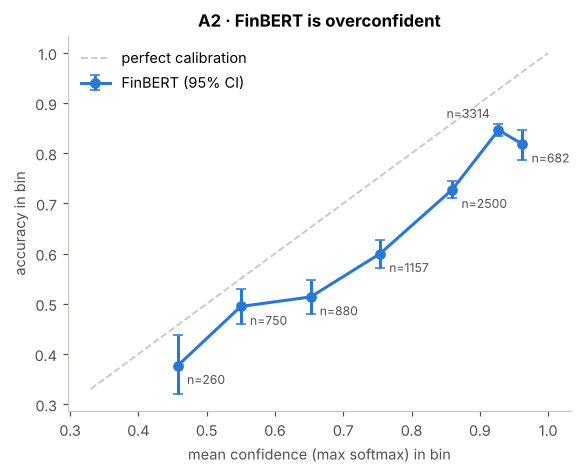

634 errors with confidence > 0.9 (23% of errors)


,cbin,n,acc,conf
0,"(0.33, 0.5]",260,0.377,0.458
1,"(0.5, 0.6]",750,0.495,0.550
2,"(0.6, 0.7]",880,0.514,0.652
3,"(0.7, 0.8]",1157,0.600,0.754
4,"(0.8, 0.9]",2500,0.728,0.860
5,"(0.9, 0.95]",3314,0.846,0.927
6,"(0.95, 1.0]",682,0.818,0.962


In [3]:
# A2 · Calibration: does confidence mean what it says?
bins = [.33, .5, .6, .7, .8, .9, .95, 1.0]
cal = d.assign(cbin=pd.cut(d.confidence, bins)).groupby("cbin", observed=True).agg(n=("correct", "size"), acc=("correct", "mean"), conf=("confidence", "mean")).reset_index()
lo, hi = map(np.array, zip(*[wilson(a*n, n) for a, n in zip(cal.acc, cal.n)]))
fig, ax = plt.subplots(figsize=(5.4, 4.4))
ax.plot([.33, 1], [.33, 1], ls="--", c="#c8c7c0", lw=1.2, label="perfect calibration")
ax.errorbar(cal.conf, cal.acc, yerr=[cal.acc - lo, hi - cal.acc], fmt="o-", c=BLUE, lw=2, ms=6, capsize=3, label="FinBERT (95% CI)")
for i, (x, y, n) in enumerate(zip(cal.conf, cal.acc, cal.n)):
    ax.annotate(f"n={n}", (x, y), xytext=(-34, 8) if i == len(cal) - 2 else (6, -12), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("mean confidence (max softmax) in bin"); ax.set_ylabel("accuracy in bin"); ax.legend(frameon=False, loc="upper left")
ax.set_title("A2 · FinBERT is overconfident")
plt.tight_layout(); plt.savefig("figures/A2_calibration.png", dpi=160); plt.show()
print(f"{(e.confidence > .9).sum()} errors with confidence > 0.9 ({(e.confidence > .9).mean():.0%} of errors)")
cal.round(3)

## B · Neutral direction
Main question: **why does FinBERT give a sentiment to tweets that humans labelled Neutral?**

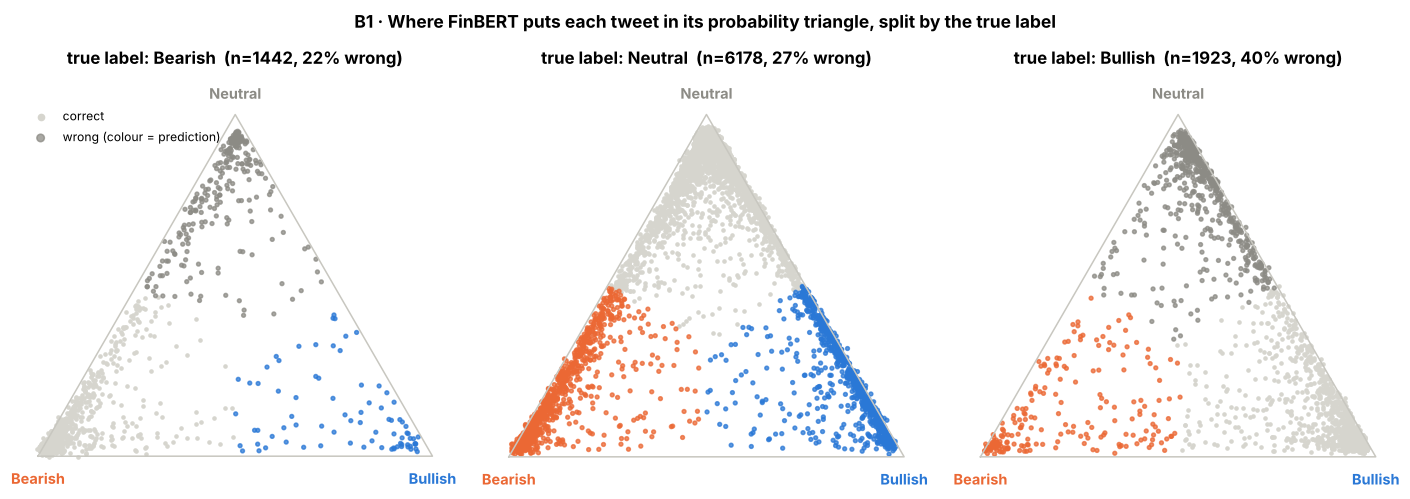

In [4]:
# B1 · The probability triangle: every tweet placed by FinBERT's 3 softmax scores (FinBERT outputs only)
# Corners = 100% Bearish / Neutral / Bullish. Points near a corner = confident; near the middle = unsure.
CORNERS = {"Bearish": (0, 0), "Bullish": (1, 0), "Neutral": (.5, np.sqrt(3)/2)}
def tri_xy(df):
    x = df.p_bearish*CORNERS["Bearish"][0] + df.p_bullish*CORNERS["Bullish"][0] + df.p_neutral*CORNERS["Neutral"][0]
    y = df.p_bearish*CORNERS["Bearish"][1] + df.p_bullish*CORNERS["Bullish"][1] + df.p_neutral*CORNERS["Neutral"][1]
    return x, y
d["tx"], d["ty"] = tri_xy(d)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
rng = np.random.default_rng(0)
for ax, c in zip(axes, ORDER):
    s = d[d.true == c]; j = rng.normal(0, .006, (len(s), 2))
    ax.plot([0, 1, .5, 0], [0, 0, np.sqrt(3)/2, 0], c="#c8c7c0", lw=1)
    for name, (cx, cy) in CORNERS.items():
        ax.text(cx, cy + (.04 if name == "Neutral" else -.07), name, ha="center", color=CLS[name], weight="bold")
    ax.scatter(s.tx[s.correct] + j[s.correct.values, 0], s.ty[s.correct] + j[s.correct.values, 1], s=4, c=LIGHT, label="correct")
    w = ~s.correct.values
    ax.scatter(s.tx[~s.correct] + j[w, 0], s.ty[~s.correct] + j[w, 1], s=6, c=[CLS[p] for p in s.pred[~s.correct]], alpha=.75, label="wrong (colour = prediction)")
    ax.set_title(f"true label: {c}  (n={len(s)}, {s.err.mean():.0%} wrong)", pad=22); ax.axis("off"); ax.set_aspect("equal")
axes[0].legend(frameon=False, loc="upper left", markerscale=2, fontsize=8)
fig.suptitle("B1 · Where FinBERT puts each tweet in its probability triangle, split by the true label", weight="bold", y=.99)
plt.tight_layout(rect=(0, 0, 1, .93)); plt.savefig("figures/B1_probability_triangle.png", dpi=160); plt.show()

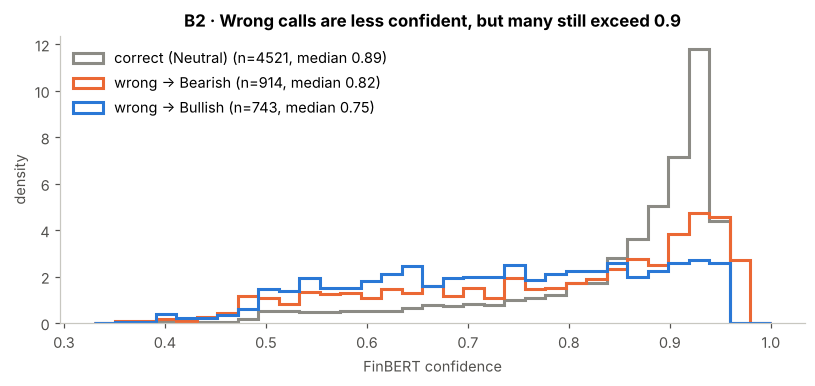

,count,mean,std,min,50%,max,share_above_0_9
group,,,,,,,
correct (Neutral),4521.0,0.85,0.11,0.35,0.89,0.96,0.46
wrong → Bearish,914.0,0.78,0.15,0.36,0.82,0.98,0.32
wrong → Bullish,743.0,0.73,0.14,0.37,0.75,0.96,0.15


In [5]:
# B2 · Are the Neutral disagreements confident or unsure? (Sarang's question)
N = d[d.true == "Neutral"].copy()
N["group"] = np.where(N.correct, "correct (Neutral)", "wrong → " + N.pred)
groups = ["correct (Neutral)", "wrong → Bearish", "wrong → Bullish"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
b = np.linspace(.33, 1, 34)
for g, col in zip(groups, [GRAY, ORANGE, BLUE]):
    v = N.confidence[N.group == g]
    ax.hist(v, bins=b, histtype="step", lw=2, color=col, density=True, label=f"{g} (n={len(v)}, median {v.median():.2f})")
ax.set_xlabel("FinBERT confidence"); ax.set_ylabel("density"); ax.legend(frameon=False, loc="upper left")
ax.set_title("B2 · Wrong calls are less confident, but many still exceed 0.9")
plt.tight_layout(); plt.savefig("figures/B2_neutral_confidence.png", dpi=160); plt.show()
N.groupby("group").confidence.describe(percentiles=[.5]).round(2).assign(share_above_0_9=N.groupby("group").confidence.apply(lambda v: (v > .9).mean()).round(2))

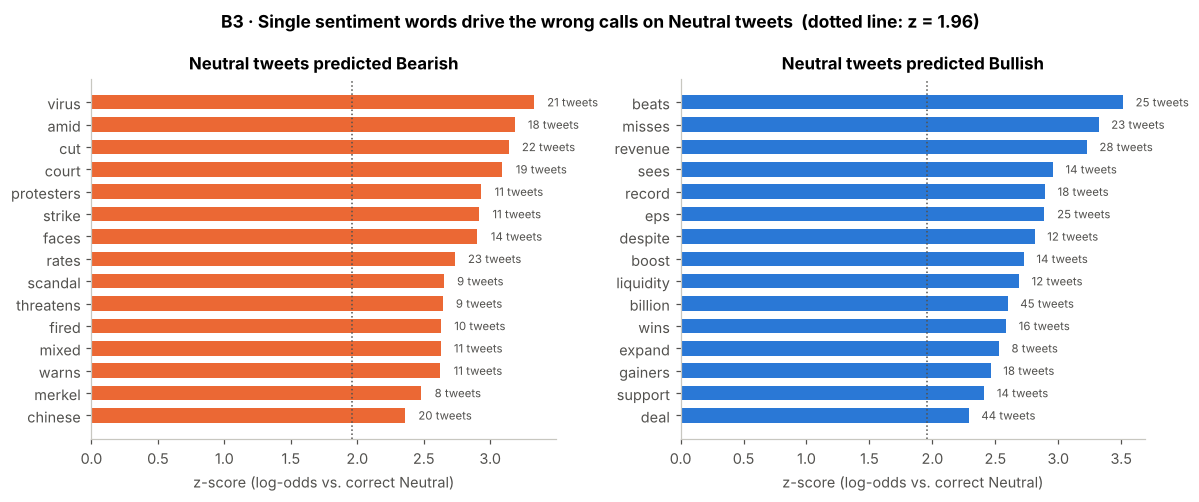

{'wrong → Bearish': ['virus',
  'amid',
  'cut',
  'court',
  'protesters',
  'strike',
  'faces',
  'rates',
  'scandal',
  'threatens',
  'fired',
  'mixed',
  'warns',
  'merkel',
  'chinese'],
 'wrong → Bullish': ['beats',
  'misses',
  'revenue',
  'sees',
  'record',
  'eps',
  'despite',
  'boost',
  'liquidity',
  'billion',
  'wins',
  'expand',
  'gainers',
  'support',
  'deal']}

In [6]:
# B3 · Which words push Neutral tweets to Bearish / Bullish? (Sarang's question)
# Weighted log-odds with an informative prior (Monroe et al. 2008): words over-represented in the
# wrong group vs. Neutral tweets FinBERT got right. Only words in >= 8 tweets.
clean = N.text.str.lower().str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\$[a-z]+", " ", regex=True)
cv = CountVectorizer(stop_words="english", min_df=8, binary=True, token_pattern=r"(?u)\b[a-z][a-z]+\b")
X = cv.fit_transform(clean); voc = np.array(cv.get_feature_names_out())
prior = np.asarray(X.sum(0)).ravel() + 1; a0 = prior.sum()
def logodds(m1, m2):
    y1, y2 = np.asarray(X[m1].sum(0)).ravel(), np.asarray(X[m2].sum(0)).ravel(); n1, n2 = y1.sum(), y2.sum()
    l1 = np.log((y1 + prior) / (n1 + a0 - y1 - prior)); l2 = np.log((y2 + prior) / (n2 + a0 - y2 - prior))
    return (l1 - l2) / np.sqrt(1/(y1 + prior) + 1/(y2 + prior)), y1
ok = (N.group == "correct (Neutral)").values
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
top_words = {}
for ax, g, col in zip(axes, ["wrong → Bearish", "wrong → Bullish"], [ORANGE, BLUE]):
    z, cnt = logodds((N.group == g).values, ok)
    idx = np.argsort(-z)[:15][::-1]; top_words[g] = list(voc[idx][::-1])
    ax.barh(voc[idx], z[idx], color=col, height=.65)
    for i, k in enumerate(idx): ax.text(z[k] + .1, i, f"{int(cnt[k])} tweets", va="center", fontsize=7.5, color=INK)
    ax.set_title(f"Neutral tweets predicted {g.split('→ ')[1]}"); ax.set_xlabel("z-score (log-odds vs. correct Neutral)")
    ax.axvline(1.96, ls=":", c=INK, lw=1)
fig.suptitle("B3 · Single sentiment words drive the wrong calls on Neutral tweets  (dotted line: z = 1.96)", weight="bold")
plt.tight_layout(); plt.savefig("figures/B3_neutral_trigger_words.png", dpi=160); plt.show()
top_words

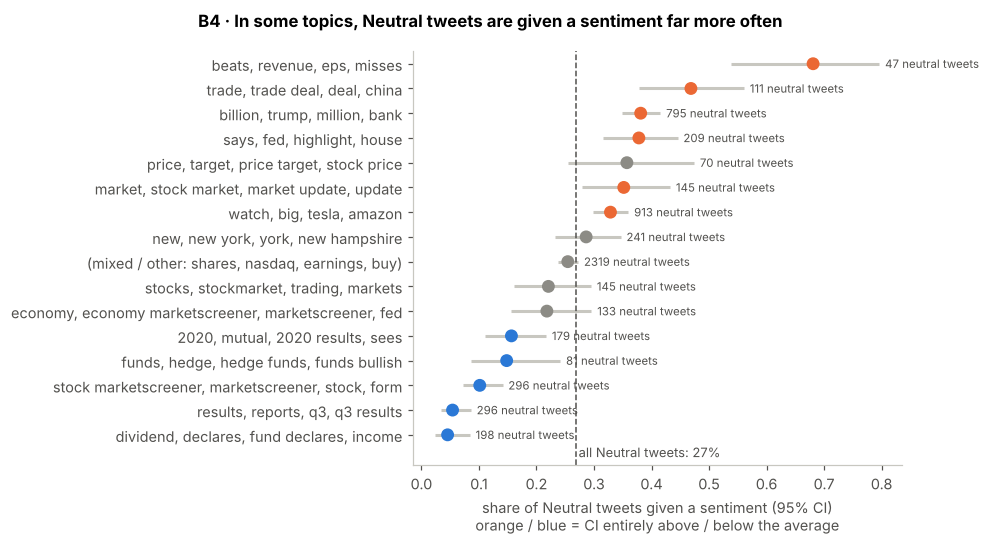

,topic_id,topic,n,err,neutral,neutral_err,main_error
12,12,"beats, revenue, eps, misses",205,0.34,0.23,0.68,Bullish → Neutral
10,10,"trade, trade deal, deal, china",225,0.34,0.49,0.47,Neutral → Bearish
8,8,"billion, trump, million, bank",996,0.38,0.80,0.38,Neutral → Bearish
13,13,"says, fed, highlight, house",302,0.35,0.69,0.38,Neutral → Bearish
11,11,"price, target, price target, stock price",260,0.27,0.27,0.36,Bullish → Neutral
0,0,"market, stock market, market update, update",292,0.30,0.50,0.35,Neutral → Bearish
15,15,"watch, big, tesla, amazon",1234,0.33,0.74,0.33,Neutral → Bearish
4,4,"new, new york, york, new hampshire",336,0.29,0.72,0.29,Neutral → Bullish
3,3,"(mixed / other: shares, nasdaq, earnings, buy)",3803,0.28,0.61,0.25,Neutral → Bearish
9,9,"stocks, stockmarket, trading, markets",284,0.26,0.51,0.22,Neutral → Bearish


In [7]:
# B4 · Topic groups from plain word counts (TF-IDF → SVD(100) → k-means; no neural model)
# k-means directly on sparse TF-IDF puts most tweets into one blob, so we first reduce to 100 dimensions (LSA).
d["clean"] = d.text.str.lower().str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\$[a-z]+", " ", regex=True)
tf = TfidfVectorizer(stop_words="english", min_df=5, max_df=.3, ngram_range=(1, 2), sublinear_tf=True)
Xt = tf.fit_transform(d.clean); tv = np.array(tf.get_feature_names_out())
K = 16
Z = make_pipeline(TruncatedSVD(100, random_state=0), Normalizer()).fit_transform(Xt)
d["topic_id"] = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(Z)
g = np.asarray(Xt.mean(0)).ravel(); rows = []
for c in range(K):
    m = (d.topic_id == c).values; s = d[m]
    terms = tv[np.argsort(-(np.asarray(Xt[m].mean(0)).ravel() - g))[:4]]
    mk = s[s.err].groupby(["true", "pred"]).size()
    rows.append(dict(topic_id=c, topic=", ".join(terms), n=m.sum(), err=s.err.mean(), neutral=(s.true == "Neutral").mean(),
                     neutral_err=s[s.true == "Neutral"].err.mean(), main_error=" → ".join(mk.idxmax()) if len(mk) else ""))
P = pd.DataFrame(rows)
P.loc[P.n.idxmax(), "topic"] = "(mixed / other: " + P.loc[P.n.idxmax(), "topic"] + ")"   # the leftover catch-all group
P = P.sort_values("neutral_err")
d["topic"] = d.topic_id.map(P.set_index("topic_id").topic)

fig, ax = plt.subplots(figsize=(9, 5))
NB = 1 - N.correct.mean()
lo, hi = map(np.array, zip(*[wilson(r.neutral_err * r.n * r.neutral, r.n * r.neutral) for r in P.itertuples()]))
ax.errorbar(P.neutral_err, P.topic, xerr=[P.neutral_err - lo, hi - P.neutral_err], fmt="none", ecolor="#c8c7c0", lw=2)
ax.scatter(P.neutral_err, P.topic, s=55, zorder=3, c=[ORANGE if l > NB else BLUE if h < NB else GRAY for l, h in zip(lo, hi)])
ax.axvline(NB, ls="--", c=INK, lw=1); ax.text(NB + .005, -.9, f"all Neutral tweets: {NB:.0%}", fontsize=8.5, color=INK)
for r, h in zip(P.itertuples(), hi): ax.text(h + .01, r.topic, f"{int(r.n * r.neutral)} neutral tweets", va="center", fontsize=7.5, color=INK)
ax.set_xlabel("share of Neutral tweets given a sentiment (95% CI)\norange / blue = CI entirely above / below the average"); ax.set_ylim(-1.2, K - .5)
fig.suptitle("B4 · In some topics, Neutral tweets are given a sentiment far more often", weight="bold", fontsize=11)
plt.tight_layout(); plt.savefig("figures/B4_topics_neutral_error.png", dpi=160); plt.show()
P.sort_values("neutral_err", ascending=False).round(2)

In [8]:
# Read examples from the worst topics: this is where the "why" comes from
for t in P.sort_values("neutral_err", ascending=False).topic.head(3):
    s = d[(d.topic == t) & (d.true == "Neutral") & d.err]
    print(f"\n=== {t}  ({len(s)} wrong Neutral tweets)")
    print(s.sample(min(8, len(s)), random_state=1)[["text", "pred", "confidence"]].assign(text=lambda x: x.text.str[:100]).to_string(index=False))


=== beats, revenue, eps, misses  (32 wrong Neutral tweets)
                                                                                           text    pred  confidence
                                          TransDigm Group EPS beats by $0.34, misses on revenue Bullish    0.661488
$DVA - DaVita HealthCare Partners EPS beats by $0.26, misses on revenue https://t.co/TipgMhhGpE Bullish    0.724346
                                                   Qudian EPS misses by $0.04, beats on revenue Bearish    0.599442
                                          LiveXLive Media EPS beats by $0.01, misses on revenue Bullish    0.845181
                                                Rada Electronics EPS in-line, misses on revenue Bullish    0.589041
                                                   Kohl's EPS misses by $0.12, beats on revenue Bullish    0.573419
                                     Patterson-UTI Energy EPS misses by $0.02, beats on revenue Bearish    0.480798
            

In [9]:
# B5 · Tweets mentioning several companies: is the single label ambiguous? (Sarang's question)
d["n_tickers"] = d.text.str.count(r"\$[A-Za-z]{1,5}\b")
d["tick_grp"] = pd.cut(d.n_tickers, [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
tk = d.groupby("tick_grp", observed=True).agg(n=("err", "size"), err=("err", "mean"), neutral=("true", lambda s: (s == "Neutral").mean()))
k, n, p = test(d.n_tickers >= 2)
print(f"tweets with >= 2 tickers: n={n}, error {k/n:.3f} vs {d.err[d.n_tickers < 2].mean():.3f} (p={p:.1e})")
tk.round(3)

tweets with >= 2 tickers: n=217, error 0.382 vs 0.286 (p=2.4e-03)


,n,err,neutral
tick_grp,,,
0,8112,0.285,0.669
1,1214,0.292,0.530
2,79,0.392,0.544
3+,138,0.377,0.478


## C · Other systematic slices (all classes)

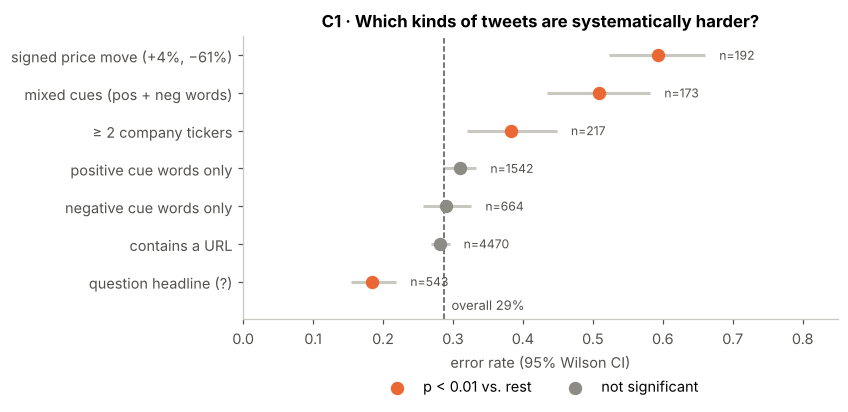

,slice,n,err,p,main_error
5,question headline (?),543,0.184,1.3e-08,Neutral → Bearish
6,contains a URL,4470,0.282,2.3e-01,Neutral → Bearish
3,negative cue words only,664,0.291,8.6e-01,Neutral → Bearish
2,positive cue words only,1542,0.310,3.7e-02,Neutral → Bullish
4,≥ 2 company tickers,217,0.382,2.4e-03,Bullish → Neutral
1,mixed cues (pos + neg words),173,0.509,8.2e-10,Neutral → Bearish
0,"signed price move (+4%, −61%)",192,0.594,5.7e-19,Bullish → Neutral


In [10]:
POS = r"\b(?:rise|rises|rose|surge|surges|soar|soars|jump|jumps|gain|gains|beat|beats|up|upgrade|upgraded|raises?|record|rally|rallies|strong|boost|higher|growth|profit|tops?)\b"
NEG = r"\b(?:fall|falls|fell|drop|drops|decline|declines|slide|slides|loss|losses|miss|misses|cut|cuts|downgrade|downgraded|lower|weak|plunge|sink|sinks|worst|risk|warns?|crisis|slump)\b"
hp, hn = T.str.contains(POS), T.str.contains(NEG)
SLICES = {
    "signed price move (+4%, −61%)": d.text.str.contains(r"[+-]\d+(?:\.\d+)?%"),
    "mixed cues (pos + neg words)": hp & hn,
    "positive cue words only": hp & ~hn,
    "negative cue words only": hn & ~hp,
    "≥ 2 company tickers": d.n_tickers >= 2,
    "question headline (?)": d.text.str.contains(r"\?"),
    "contains a URL": d.text.str.contains(r"https?://"),
}
rows = []
for name, m in SLICES.items():
    k, n, p = test(m); l, h = wilson(k, n); top = e[m[e.index]].groupby(["true", "pred"]).size()
    rows.append(dict(slice=name, n=n, err=k/n, lo=l, hi=h, p=p, main_error=" → ".join(top.idxmax()) if len(top) else ""))
S = pd.DataFrame(rows).sort_values("err")
fig, ax = plt.subplots(figsize=(7.8, 3.9)); sig = S.p < .01
ax.errorbar(S.err, S.slice, xerr=[S.err - S.lo, S.hi - S.err], fmt="none", ecolor="#c8c7c0", lw=2)
ax.scatter(S.err[sig], S.slice[sig], s=60, c=ORANGE, zorder=3, label="p < 0.01 vs. rest")
ax.scatter(S.err[~sig], S.slice[~sig], s=60, c=GRAY, zorder=3, label="not significant")
ax.axvline(BASE, ls="--", c=INK, lw=1); ax.text(BASE + .01, -.75, f"overall {BASE:.0%}", color=INK, fontsize=8.5)
for r in S.itertuples(): ax.text(r.hi + .02, r.slice, f"n={r.n}", va="center", color=INK, fontsize=8)
ax.set_xlim(0, .85); ax.set_ylim(-1, len(S) - .5); ax.set_xlabel("error rate (95% Wilson CI)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2)
ax.set_title("C1 · Which kinds of tweets are systematically harder?")
plt.tight_layout(); plt.savefig("figures/C1_slices.png", dpi=160); plt.show()
S.assign(err=S.err.round(3), p=S.p.map("{:.1e}".format)).drop(columns=["lo", "hi"])

In [11]:
# C2 · Signed price moves: does FinBERT read the sign?
sign = d.text.str.extract(r"([+-])\d+(?:\.\d+)?%")[0]
s = d[sign.notna()].assign(sign=sign.dropna().map({"+": "+x%", "-": "−x%"}))
pd.crosstab([s.sign, s.true], s.pred, margins=True)

pred          Bearish  Bullish  Neutral  All
sign true                                   
+x%  Bearish        3        0        0    3
     Bullish       10       46       71  127
     Neutral        2        2        1    5
−x%  Bearish       23       13       16   52
     Bullish        0        1        0    1
     Neutral        0        0        4    4
All                38       62       92  192

## D · Manual review sample
Exports 120 wrong Neutral tweets, split evenly over confidence (low / medium / high), to judge by hand:
- `model_mistake`: the label is clearly right, FinBERT is wrong
- `ambiguous`: reasonable people could disagree (tone vs. stock signal)
- `label_wrong`: the dataset label itself looks wrong

In [12]:
wn = N[~N.correct].copy()
wn["conf_band"] = pd.cut(wn.confidence, [0, .7, .9, 1], labels=["low (<0.7)", "mid (0.7–0.9)", "high (>0.9)"])
review = pd.concat([g.sample(min(40, len(g)), random_state=42) for _, g in wn.groupby("conf_band", observed=True)])
review = review[["text", "true", "pred", "confidence", "conf_band"]]
review["verdict"] = ""; review["note"] = ""
review.to_csv("manual_review_neutral.csv", index_label="row_id")
print(len(review), "tweets exported to manual_review_neutral.csv"); review.conf_band.value_counts()

120 tweets exported to manual_review_neutral.csv


conf_band
low (<0.7)       40
mid (0.7–0.9)    40
high (>0.9)      40
Name: count, dtype: int64

## Notes for interpretation
- Cue-word lists, k = 16 topics and the confidence bands are our own choices: they help find hypotheses, they are not ground truth.
- Working hypothesis: in this dataset *Neutral* means "no clear stance on a specific stock", while FinBERT (trained on Financial PhraseBank) judges the *tone* of a sentence.
  B3–B4 and the manual review (D) test this: if most wrong Neutral tweets carry strong tone words and are judged `ambiguous`, the hypothesis holds.